In [82]:
def plot(image):
    image=np.array(image, dtype=np.uint8)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.show()

## Image Enhancement

In [83]:
import numpy as np
import os
import cv2
from PIL import Image
import matplotlib.pyplot as plt

just read the image

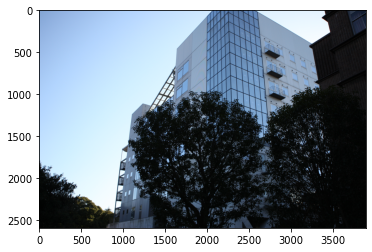

In [84]:
image=cv2.imread('image1.jpg')
plot(image)

we apply few mask on the image that change every mask separately

In [85]:
indicator=np.array([[1 if image[j,i,0]<20 and image[j,i,1]<20and image[j,i,2]<20 else 0 for i in range(image.shape[1])] for j in range(image.shape[0])])

indicator2=np.array([[1 if image[j,i,0]>150 or image[j,i,1]>150 or image[j,i,2]>150 else 0 for i in range(image.shape[1])] for j in range(image.shape[0])])

indicator3=1-indicator-indicator2

for i in range(indicator3.shape[0]):
    for j in range(indicator3.shape[1]):
        if(indicator3[i,j]<0):
            indicator3[i,j]=0

the work that we do in every mask

In [86]:
def Do(indicator,action,image,number):
    im=np.zeros((image.shape))
    for i in range(3):
        im[:,:,i]=image[:,:,i]*indicator
        if(action=="mult"):
            im[:,:,i]*=[[number]]
        elif(action=="plus"):
             im[:,:,i]+=[[number]]
        else:
            print("action is not detected")
    return im

tha image is ok but in this plot it doesn't seam correctly

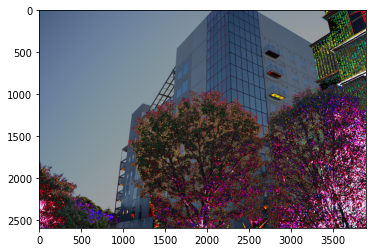

In [87]:
im1 = Do(indicator ,"mult",image,5  )
im2 = Do(indicator2,"mult",image,0.7)
im3 = Do(indicator3,"plus",image,-20)

new_image=im1+im2+im3
cv2.imwrite('image2.jpg‬‬',new_image)
plot(new_image)

## Image Enhancement(Histogram Processing)

In [88]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import pandas as pd
from PIL import Image

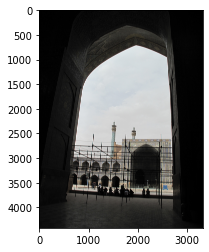

In [89]:
image=cv2.imread('image3.JPG')
plot(image)

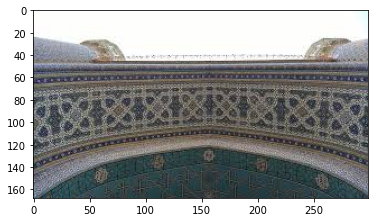

In [90]:
image1=cv2.imread('dist.jpg')
plot(image1)

to get distribution of color in an image

In [91]:
def dist(image):
    A=np.zeros((3,256))
    for j in range(3):
        channel_image=image[:,:,j]
        a=channel_image.size
        channel_image=channel_image.reshape((1,a))
        channel_image=channel_image[0]

        channel_image_total=np.zeros(256)
        for i in range(channel_image.size):
            channel_image_total[channel_image[i]]+=1
        for i in range(1,256):
            channel_image_total[i]=channel_image_total[i]+channel_image_total[i-1]
        channel_image_total/=channel_image.size
        A[j,:]=channel_image_total
    
    return A

in this function we just calculate color for image based on the distributution than we apply it on the image than return it as final image

In [92]:
def preapreation(image,image2):
    
    
    total=dist(image)*image.size/3
    new_total=dist(image2)*image.size/3
    
    new_dist=np.zeros((3,256))
    final_image=np.zeros(image.shape)
    for i in range(3):
        new_image=image[:,:,i].copy()
        for j in range(256):
            for k in range(256):
                if(total[i,j]<=new_total[i,k]):
                    new_dist[i,j]=k
                    break
                    
        new_dist[i,0]=new_dist[i,0]/2
        for j in range(1,256):
            new_dist[i,j]=(new_dist[i,j]+new_dist[i,j-1])/2          
        
        
        for j in range(256):
            new_image[image[:,:,i]==j]=new_dist[i,j]
        final_image[:,:,i]=new_image
        
    return final_image

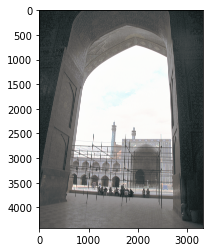

In [93]:
new_image=preapreation(image,image1)
cv2.imwrite('image4.jpg‬‬',new_image)
plot(new_image)

## Edge Detection

In [94]:
import scipy.signal

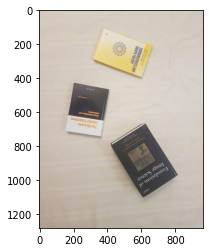

In [95]:
image=cv2.imread("image5.jpg")
plot(image)

In [96]:
image=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)

we apply a a gussioan filter on the every dimention

In [97]:
def filter_maker(n,sigma,c):
    if(c=="X"):
        return  np.array([[(((n-1)/2-x)/(np.pi*2*sigma**4))*np.exp(-((x-(n-1)/2)**2+(y-(n-1)/2)**2)/(2*sigma**2)) for x in range(7)]for y in range(7)])
    elif(c=="Y"):
        return  np.array([[(((n-1)/2-y)/(np.pi*2*sigma**4))*np.exp(-((x-(n-1)/2)**2+(y-(n-1)/2)**2)/(2*sigma**2)) for x in range(7)]for y in range(7)])

In [98]:
filterx=filter_maker(7,1,"X")
filtery=filter_maker(7,1,"Y")

than we convolve the filters on the image and use summation on it 

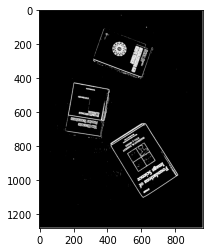

In [99]:
image1=scipy.signal.convolve2d(image,filterx,mode='same')
image2=scipy.signal.convolve2d(image,filtery,mode='same')
image3=np.sqrt(np.multiply(image1,image1)+np.multiply(image2,image2))

#apply a limit on the edges for mare than 7 we assum that it's a edge
image4=np.vectorize(lambda x : 255  if x>7  else 0)(image3)

cv2.imwrite("image6.jpg‬‬",image4)
plot(image4)

## Line Detection

we find edge buy canny then we make evey possible line for evey dote than rate the line and get maximoms

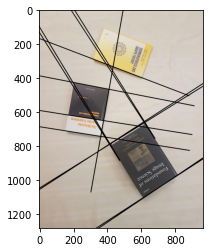

In [100]:
image=cv2.imread("image5.jpg")
gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(gray,100,200,apertureSize = 3)

lines = cv2.HoughLines(edges,1,np.pi/180.0,150, np.array([]), 10, 20)

for line in lines:
    rho, theta = line[0]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a*rho
    y0 = b*rho
    x1 = int(x0 + 1000*(-b))
    y1 = int(y0 + 1000*(a))
    x2 = int(x0 - 1000*(-b))
    y2 = int(y0 - 1000*(a))

    cv2.line(image,(x1,y1),(x2,y2),(0,0,0),4)
    
cv2.imwrite('image7.jpg',image)
plot(image)

## Hybrid Images

here we make image of two doffrent image that in near we can see the on image and at the far distance we can see another image

In [101]:
import numpy as np
import os
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import scipy.signal

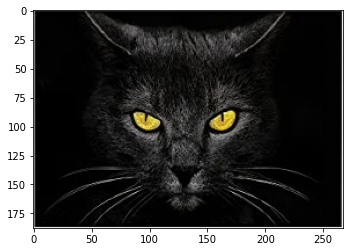

In [102]:
image1=cv2.imread("image8.jpg")
image1=cv2.resize(image1,(268,188),interpolation=cv2.INTER_CUBIC)
plot(image1)

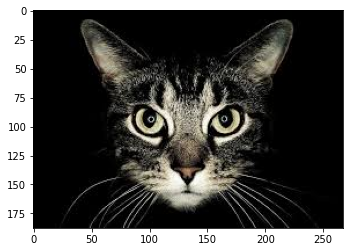

In [103]:
image2=cv2.imread("image9.jpeg")
plot(image2)

here we get laplacian of the image than we make a hole in the laplacian and put near image' hole in the middel of the outher image and make inverse of laplacian than it's the final image

In [104]:
def fft(image):
    shifted=[]
    for a in range(3):
        new=np.fft.fftshift(np.fft.fft2(image[:,:,a]))
        shifted.append(new)
    return np.array(shifted)

In [105]:
def high_pass(image,r):
    mn=np.zeros((image.shape[0],image.shape[1]))
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            a=image.shape[0]//2
            b=image.shape[1]//2
            mn[i,j]=np.exp(-d(i,j,a,b)**2/(2*r**2))
    return mn

def d(u,v,a,b):
    return np.sqrt((u-a)**2+(v-b)**2)

def low_pass(image,s):
    return (1-high_pass(image,s))

def cutoff(image,cutoff):
    cutoffmat=np.zeros((image.shape[0],image.shape[1]))
    a=image.shape[0]//2
    b=image.shape[1]//2
    for x in range(image.shape[0]):
        for y in range(image.shape[1]):
            if((x-a)**2+(y-b)**2<= cutoff**2):
                cutoffmat[x,y]=1
    return cutoffmat

def result(image1,cutoff_low,image2,cutoff_high,c,b):
    shifted1=fft(image1)
    shifted2=fft(image2)
    new_image=np.zeros(image2.shape)
    for i in range(3):
        a=(np.multiply(shifted1[i,:,:],cutoff_low))*c + (np.multiply(shifted2[i,:,:],cutoff_high))*b
        new_image[:,:,i]=np.real(np.fft.ifft2(np.fft.ifftshift(a)))
    return new_image.reshape((image2.shape[0],image2.shape[1],3))


plot isn't show correctly check the saved image

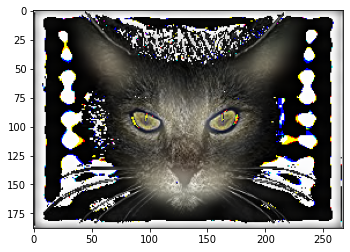

In [211]:
cutoff_high=np.multiply(cutoff(image2,10),high_pass(image2,5))
cutoff_low=np.multiply(1-cutoff(image1,10),low_pass(image1,10))

imagetotal=np.zeros((image2.shape))
imagetotal=result(image1,cutoff_low,image2,cutoff_high,1,1)


cv2.imwrite("image10.jpg",imagetotal)
plot(imagetotal)

In [212]:
imagetotal2=cv2.resize(imagetotal,(67,47),interpolation=cv2.INTER_CUBIC)

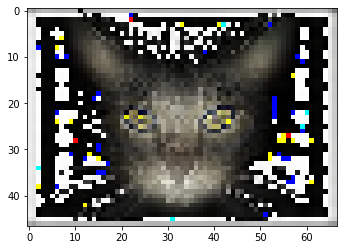

In [213]:
cv2.imwrite("image11.jpg",imagetotal2)
plot(imagetotal2)

## Graph Cut

In [28]:
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
from skimage.segmentation import slic,mark_boundaries
import argparse
import skimage.color as color
import cv2

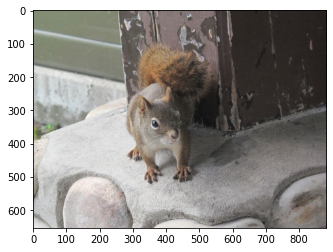

In [29]:
sanjab1=io.imread("image12.jpg")
plt.imshow(sanjab1)

<ipython-input-30-3b2e33c5370c>:1: FutureWarning: skimage.measure.label's indexing starts from 0. In future version it will start from 1. To disable this warning, explicitely set the `start_label` parameter to 1.
  segments = slic(sanjab1, n_segments = 500,sigma=3)


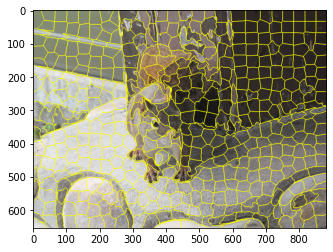

In [30]:
segments = slic(sanjab1, n_segments = 500,sigma=3)
plt.imshow(mark_boundaries(sanjab1,segments))

In [31]:
image1=color.label2rgb(segments, sanjab1, kind='avg')

<ipython-input-31-73f9aefacdd6>:1: FutureWarning: The new recommended value for bg_label is 0. Until version 0.19, the default bg_label value is -1. From version 0.19, the bg_label default value will be 0. To avoid this warning, please explicitly set bg_label value.
  image1=color.label2rgb(segments, sanjab1, kind='avg')


In [32]:
def mask(image1):
    for i in range(image1.shape[0]):
        for j in range(image1.shape[1]):
            if(np.sqrt((i-x0)**2+(j-y0)**2)>=230 ):
                mask[i,j]=0
                
        for j in range(530,image1.shape[1]):            
                if(mask[i,j]>=1):
                    mask[i,j]=0
                    
        for j in range(500,image1.shape[1]):            
                if(mask[i,j]>=1):
                    mask[i,j]=0
    return mask

we just use over segmentation and apply a mask arround it than we use graph cut on it to split the object from area

In [36]:
x0,y0=segments.shape[0]//2,segments.shape[1]//2
mask = np.zeros(image1.shape[:2],np.uint8)
bgdModel = np.zeros((1,65),np.float64)
fgdModel = np.zeros((1,65),np.float64)

rect=(246,72,400,483)            
cv2.grabCut(image1,mask,rect,bgdModel,fgdModel,5,cv2.GC_INIT_WITH_RECT)

mask2 = np.where((mask==2)|(mask==0),0,1).astype('uint8')
mask2[220:350,310:420]=1
image1 = image1*mask2[:,:,np.newaxis]

mask=mask(image1)

mask, bgdModel, fgdModel = cv2.grabCut(image1,mask,None,bgdModel,fgdModel,5,cv2.GC_INIT_WITH_MASK)

mask = np.where((mask==2)|(mask==0),0,1).astype('uint8')
mask[220:350,310:420]=1

image1=image1*mask[:,:,np.newaxis]

<ipython-input-40-e368cddc20ce>:5: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "dip" which is no longer supported as of 3.3 and will become an error two minor releases later
  plt.savefig("/home/javad/Desktop/jupyter notebook/image_processing/im06.jpg",dip=300)


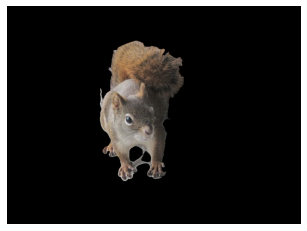

In [40]:
mask3=np.zeros(image1.shape)
mask3=np.where(image1>0,1,0)
plt.imshow(mask3*sanjab1)
plt.axis("off")
plt.savefig("image13.jpg",dip=300)
plt.show()

## Active contoure

In [33]:
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
from skimage.segmentation import slic,mark_boundaries
import argparse
import skimage.color as color
import cv2
from scipy import signal 
from PIL import Image

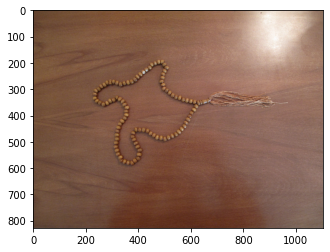

In [34]:
image=io.imread("image14.jpg")
image_gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
plt.imshow(image)

In [35]:
number_of_dots=39

In [44]:
teta = np.linspace(0, 2*np.pi,number_of_dots )
sin = image.shape[1]//2-130 + 270*np.sin(teta)
cos = image.shape[0]//2-20 + 270*np.cos(teta)
init = np.array([sin, cos],dtype='int').T

In [46]:
def gaussian_derivative(x, y, mu, sigma):
    return ((-(x - mu)) / (2 * np.pi * sigma**4)) * np.exp(-(((x - mu)**2 + (y - mu)**2) / (2 * sigma**2)))

def gaussian_derivative_filter(size, sigma, axis):
    mu = size // 2
    mat = np.zeros((size, size))
    if axis == 'x':
        for i in range(size):
            for j in range(size):
                mat[i, j] = gaussian_derivative(j, i, mu, sigma)
    else:
        for i in range(size):
            for j in range(size):
                mat[i, j] = gaussian_derivative(i, j, mu, sigma)
    return mat

def conv(image,kernel):
    return signal.convolve2d(image,kernel,mode='same')

In [47]:
imagex=conv(image_gray,gaussian_derivative_filter(5,1,0))
imagey=conv(image_gray,gaussian_derivative_filter(5,1,1))

we calculate energy function on the image and just calculte every change of it in every step

In [48]:
def chage(index,array,d,alpha,beta,gama):
    v=array[index,:]
    [x,y]=array[index,:]
    minimum=1e9 
    a,b=0,0
    x,y=int(x),int(y)
    
    for i in range(-1,2):
        for j in range(-1,2):
            vnew=np.array([y+j,x+i])
            if(y+j<image.shape[0] and x+i<image.shape[1]):
                
                E_external=(-(imagex[y+j,x+i]**2+imagey[y+j,x+i]**2)+(imagex[y,x]**2+imagey[y,x]**2))
                
                vnext=array[(index+1)%number_of_dots,:]
                vprev=array[(index-1)%number_of_dots,:]

                
                E_internal_1=((np.linalg.norm(vnew-vnext)-d)**2-(np.linalg.norm(v-vnext)-d)**2)
                E_internal_2=(np.linalg.norm(vnew+vnew-vnext-vprev))**2-(np.linalg.norm(v+v-vnext-vprev))**2

                if(gama*E_external+alpha*E_internal_1+beta*E_internal_2<minimum):
                    minimum=gama*E_external+alpha*E_internal_1+beta*E_internal_2
                    a,b=i,j
    array[index,:]=[x+a,y+b]
    return array        

In [49]:
def avrage_d(array):
    s=0
    for index in range(array.shape[0]):
        v=array[index,:]
        v2=array[(index+1)%number_of_dots,:]
        s+=np.linalg.norm(v-v2)
    return s/array.shape[0]  

try to make a Gif

In [50]:
for j in range(500):
    for i in range(number_of_dots):
        init=chage(i,init,avrage_d(init),1,0.01,10)
    if(j%5==0):
        data=np.zeros((init.shape[0]+1,2))
        data[:init.shape[0],:]=init
        data[init.shape[0],:]=init[0,:]
        plt.imshow(image)
        plt.plot(data[:,0],data[:,1],color='blue')
        plt.scatter(data[:,0],data[:,1],color='orange')
        plt.savefig("/frame/" + str(j)+ ".jpg")
        plt.clf()
        

<Figure size 432x288 with 0 Axes>

In [51]:
image_frame = []
for i in range(0, 500, 5):
    pltimage = cv2.imread("/frame/" + str(i)+ ".jpg")
    height, width, layers = pltimage.shape
    size = (width, height)
    image_frame.append(pltimage)

In [52]:
out = cv2.VideoWriter("movie01.mp4", cv2.VideoWriter_fourcc(*'DIVX'), 5, size)

for i in range(len(image_frame)):
        out.write(image_frame[i])
out.release()

## Texture Synthesis

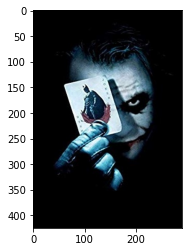

In [109]:
image=cv2.imread("image15.jpg")
plot(image)

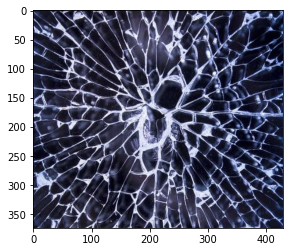

In [110]:
texture=cv2.imread("image16.jpg")
plot(texture)

Hyper paramters

In [111]:
texture=cv2.resize(texture,(image.shape[1],image.shape[0]))
new_high,new_width=image.shape[:2]
overlap=2
batchsize=10
alpha=0.3
new_image=np.zeros((new_high,new_width,3))

In [112]:
a=np.random.randint(image.shape[0]//batchsize-1)
b=np.random.randint(image.shape[1]//batchsize-1)
new_image[0:batchsize,0:batchsize]=image[a*batchsize:(a+1)*batchsize,b*batchsize:(b+1)*batchsize]

we apply a mach making to find best place of texture image for mapping to the final image's part 

In [113]:
def match_maker(image,i,j):
    template=np.zeros((batchsize,batchsize,3))
    if(i==batchsize ):
        x=min(j-batchsize+overlap,image.shape[1])
        template[:,0:x+batchsize-j]=image[:i,j-batchsize:x]
    if(j==batchsize and i!=batchsize):
        y=min(i-batchsize+overlap,image.shape[0])
        template[0:y+batchsize-i,:]=image[i-batchsize:y,:batchsize]    
    if(i!=batchsize and j!=batchsize):
        max_x=min(image.shape[1],j)
        max_y=min(image.shape[0],i)
        x=min(j-batchsize+overlap,max_x)
        y=min(i-batchsize+overlap,max_y) 
        template[:max_y+batchsize-i,:max_x+batchsize-j]=image[i-batchsize:max_y,j-batchsize:max_x]
        template[y+batchsize-i:,x+batchsize-j:]=0  
    
    
    mask=np.vectorize(lambda x: 1 if x>=0 else 0)(template)
    template=template.astype(np.uint8)
    return template, mask

def all_neighber(i,j,mask):
    neighber=[]
    for s in range(-1,2):
        for t in range(-1,2):
            if(0<=s+i<mask.shape[0] and 0<=j+t<mask.shape[1] and not(s==0 and t==0)):
                neighber.append([i+s,j+t])
    return neighber 


def type_mask(mask):
    k,l=0,0
    type_mask=1
    for i in range(mask.shape[0]):
        if(mask[i,mask.shape[1]-1,0]!=0):
            k=i
    for j in range(mask.shape[1]):
         if(mask[mask.shape[0]-1,j,0].any()!=0):
                l=j
    if(k!=0 and l!=0):
        type_mask=2
    if(k==0 and l!=0):
        type_mask=1
    if(l==0 and k!=0):
        type_mask=3
    return type_mask,k,l


In [114]:
def min_cut(mask,image):
    min_cut=np.zeros((mask.shape[0],mask.shape[1]))
    type_m,k,l=type_mask(mask)
    result=np.zeros((mask.shape[0],mask.shape[1]))
    
    if(type_m==1):
        for i in range(image.shape[0]):
            for j in range(l+1):
                for x,y in all_neighber(i,j,mask):
                    if(mask[x,y,:].all()==1):
                        total=min_cut[i,j]+np.linalg.norm(image[x,y,:]-image[i,j,:])
                        if(min_cut[x,y]==0 or min_cut[x,y]>total):
                            min_cut[x,y]=total
                    else:
                        min_cut[x,y]=0
        min_cut[:k,:]=0
        min_cut[mask.shape[0]-1,:]=0
        
        
        minimum=1e9
        s,t=image.shape[0]-2,0
        for j in range(l+1):
            if(minimum > min_cut[s,j]):
                minimum=min_cut[s,j]
                t=j
        result[s,t]=1
        result[s+1,t]=1
        while(s!=0):
            minimum=1e9
            g,v=0,0
            for x,y in all_neighber(s,t,mask):
                if(min_cut[x,y]<minimum and result[x,y]==0 and mask[x,y,:].all()!=0 and x!=image.shape[0]-1):
                    minimum=min_cut[x,y]
                    g,v=x,y
            s,t=g,v
            result[s,t]=1
            
        
        
        
        

        
    if(type_m==3):
        for j in range(image.shape[1]-1,-1,-1):
            for i in range(k):
                for x,y in all_neighber(i,j,mask):
                    if(mask[x,y,:].all()==1):
                        if(min_cut[x,y]==0 or min_cut[x,y]>min_cut[i,j]+np.linalg.norm(image[x,y,:]-image[i,j,:])):
                            min_cut[x,y]=min_cut[i,j]+np.linalg.norm(image[x,y,:]-image[i,j,:])
                    else:
                        min_cut[x,y]=0
        min_cut[:l,0]=0
        min_cut[:l,mask.shape[1]-1]=0
        
        minimum=1e9
        s,t=0,1
        for i in range(k+1):
            if(minimum > min_cut[j,t]):
                minimum=min_cut[j,t]
                s=i
        result[s,t]=1
        result[s,t-1]=1
        while(t!=image.shape[0]-1):
            minimum=1e9
            g,v=0,0
            for x,y in all_neighber(s,t,mask):
                if(min_cut[x,y]<minimum and result[x,y]==0 and mask[x,y,:].all()!=0 and y!=0):
                    minimum=min_cut[x,y]
                    g,v=x,y
            s,t=g,v
            result[s,t]=1
        
    if(type_m==2):
        
        result1=np.zeros(result.shape)
        result2=np.zeros(result.shape)
        
        for i in range(image.shape[0]):
            for j in range(l+1):
                for x,y in all_neighber(i,j,mask):
                    if(mask[x,y,:].all()==1):
                        total=min_cut[i,j]+np.linalg.norm(image[x,y,:]-image[i,j,:])
                        if(min_cut[x,y]==0 or min_cut[x,y]>total):
                            min_cut[x,y]=total
                    else:
                        min_cut[x,y]=0
        min_cut[:k,:]=0
        min_cut[mask.shape[0]-1,:]=0
        
        
        minimum=1e9
        s,t=image.shape[0]-2,0
        for j in range(l+1):
            if(minimum > min_cut[s,j]):
                minimum=min_cut[s,j]
                t=j
        result1[s,t]=1
        result1[s+1,t]=1
        while(s!=0):
            minimum=1e9
            g,v=0,0
            for x,y in all_neighber(s,t,mask):
                if(min_cut[x,y]<minimum and result1[x,y]==0 and mask[x,y,:].all()!=0 and x!=image.shape[0]-1):
                    minimum=min_cut[x,y]
                    g,v=x,y
            s,t=g,v
            result1[s,t]=1
        
      
        min_cut=np.zeros((mask.shape[0],mask.shape[1]))
        for j in range(image.shape[1]-1,-1,-1):
            for i in range(k):
                for x,y in all_neighber(i,j,mask):
                    if(mask[x,y,:].all()==1):
                        if(min_cut[x,y]==0 or min_cut[x,y]>min_cut[i,j]+np.linalg.norm(image[x,y,:]-image[i,j,:])):
                            min_cut[x,y]=min_cut[i,j]+np.linalg.norm(image[x,y,:]-image[i,j,:])
                    else:
                        min_cut[x,y]=0
        min_cut[:l,0]=0
        min_cut[:l,mask.shape[1]-1]=0
        
        minimum=1e9
        s,t=0,1
        for i in range(k+1):
            if(minimum > min_cut[j,t]):
                minimum=min_cut[j,t]
                s=i
        result2[s,t]=1
        result2[s,t-1]=1
        while(t!=image.shape[0]-1):
            minimum=1e9
            g,v=s,t
            for x,y in all_neighber(s,t,mask):
                if(min_cut[x,y]<minimum and result2[x,y]==0 and mask[x,y].any()!=0 and y!=0 and y>=t):
                    minimum=min_cut[x,y]
                    g,v=x,y
            s,t=g,v
            result2[s,t]=1
        
        x,y=0,0
        result=result1+result2
        for i,j in range(image.shape[0],image.shape[1]):
            if(result[i,j]==2):
                x,y=i,j
        result1[:x,:]=0
        result2[:,:y]=0
        result=result1+result2
        result[x,y]=1
        
    return result,k,l

In [115]:
def make_result_of_min_cut(mask,image):
    cut,k,l=min_cut(mask,image)
    result1=np.zeros((cut.shape[0],cut.shape[1]))
    line=[]
    
    for i in range(cut.shape[0]):
        for j in range(cut.shape[1]):
            if(cut[i,j]==0 and get_edge(cut,i,j)):
                result1[i,j]=1
    return result1,1-result1  

In [116]:
def get_edge(cut,x,y):
    boolian=True
    for i in range(x+1,cut.shape[0]):
        if(cut[i,y]==1):
            boolian=False
    if(boolian):
        for j in range(y+1,cut.shape[1]):
            if(cut[x,j]==1):
                boolian=False
    return boolian

In [117]:
for i in range(batchsize,new_image.shape[0]+batchsize-overlap-1,batchsize-overlap):
    for j in range(batchsize,new_image.shape[1]+batchsize-overlap-1,batchsize-overlap):
        
        template=np.zeros((batchsize,batchsize,3))
        template,mask=match_maker(new_image,i,j)

        match = cv2.matchTemplate(texture, template, cv2.TM_CCOEFF_NORMED)
        match2 = cv2.matchTemplate(texture,image[i-batchsize:i,j-batchsize:j], cv2.TM_CCOEFF_NORMED)
        if(match.shape!=match2.shape):
            new_match=np.zeros(match.shape)
            min0=min(match2.shape[0],match.shape[0])
            min1=min(match2.shape[1],match.shape[1])
            new_match[:min0,:min1]=match2[:min0,:min1]
            match2=new_match
          
        last=alpha*match+(1-alpha)*match2
        threshold=last.max()
        
        position = np.where(last == threshold)
        if(len(position[0])>2):
            number=np.random.randint(len(position[0]))
            a=position[0][i]
            b=position[1][i]
            position=a,b
              
        img=texture[int(position[0]):int(position[0])+batchsize,int(position[1]):int(position[1])+batchsize]
        A,B=make_result_of_min_cut(mask,template)
        new_A=np.array([A.T,A.T,A.T])
        new_B=np.array([B.T,B.T,B.T])
        new_part=np.multiply(img,new_A.T)+np.multiply(template,new_B.T)
        a,b=min(i,new_image.shape[0]),min(j,new_image.shape[1])
        new_image[i-batchsize:a,j-batchsize:b]=new_part[:a+batchsize-i,:b+batchsize-j]
        

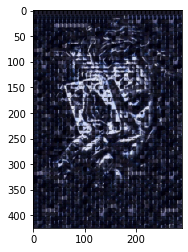

In [118]:
cv2.imwrite("image17.jpg",new_image)
plot(new_image)

## Image Blending

In [119]:
import scipy.sparse
from os import path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import spsolve
from PIL import Image

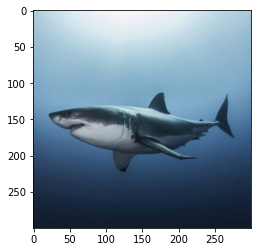

In [120]:
inner = cv2.imread("image18.jpg")
plot(inner)

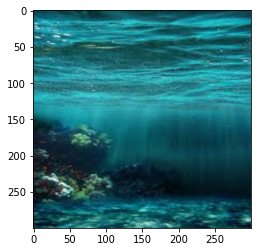

In [121]:
outher = cv2.imread("image19.jpg")
outher=cv2.resize(outher,(inner.shape[1],inner.shape[0]))
plot(outher)

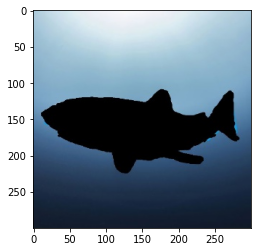

In [122]:
mask =cv2.imread("mage20.jpg")
plot(mask)

to create an image in an other image we should do some thing first we should change the distribution on the part than we should get saem result on laplacian so we should change it's result so we have a equation that should be solved

In [123]:
mask[mask>0]=1
mask[mask==0]=2
mask=mask-1
mask=(mask.sum(axis=2)+1)//3

In [124]:
def alpha_maker(inner,outher,i):
    b1=np.zeros(inner.shape[:2])
    b2=np.zeros(outher.shape[:2])
    b1 =np.abs(cv2.Laplacian( inner[:,:,i],cv2.CV_64F)*(1-mask))
    b2 =np.abs(cv2.Laplacian(outher[:,:,i],cv2.CV_64F)*mask)
    c1=b1.sum()
    c2=b2.sum()
    t=mask.sum()
    c1/=(40000-t)
    c2/=t
    return c2/c1

In [125]:
def D_maker(m):
    matrix_D = scipy.sparse.lil_matrix((m, m))
    matrix_D.setdiag(-1,-1)
    matrix_D.setdiag(4)
    matrix_D.setdiag(-1, 1)
    return matrix_D

In [126]:
def laplacian_matrix(m,n):   
    matrix_D=D_maker(m)
    matrix_A = scipy.sparse.block_diag([matrix_D] * n).tolil()
    matrix_A.setdiag(-1, m)
    matrix_A.setdiag(-1,-m)
    return matrix_A

In [127]:
def sovler(mask,inner,outher,laplacian,bool):
    mask_flated = mask.flatten()
    final=np.zeros(outher.shape)
    for i in range(3):
        inner_flated = inner[:,:,i].flatten()
        outher_flated = outher[:,:,i].flatten()  
        
    #   in here we just apply 1-mask on the answer of Ax=B
        if(bool):
            alpha=alpha_maker(inner,outher,i)
        else:
            alpha=0.9
        B = laplacian.dot(inner_flated)*alpha
        B[mask_flated == 0] = outher_flated[mask_flated == 0]
        
    #     in here we get result and use it to make final image
        result = spsolve(A, B)
        print(result.max(),result.min())
        result[result > 255] = 255
        result[result < 0] = 0
        result= np.array(result,dtype='uint8')
        result = result.reshape((inner.shape[0], inner.shape[1]))

        final[:,:,i] = result
    return final

In [128]:
def apply_mask(A,mask):
    for x in range(1, mask.shape[0] - 1):
        for y in range(1, mask.shape[1] - 1):
            if (mask[x, y]==0):
                k = y + x * mask.shape[1]
                A[k, k] = 1
                A[k, k + 1] = 0
                A[k, k - 1] = 0
                A[k, k + mask.shape[1]] = 0
                A[k, k - mask.shape[1]] = 0
    A = A.tocsc()
    return A

In [129]:
A = laplacian_matrix(outher.shape[0], outher.shape[1])
laplacian = A.tocsc()

In [130]:
A=apply_mask(A,mask)

In [131]:
final=sovler(mask,inner,outher,laplacian,False)

253.0 9.0
252.0 4.0
242.0 -57.54314868429024


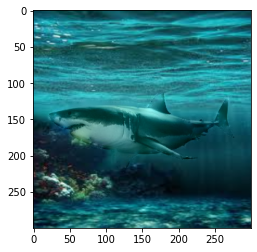

In [132]:
cv2.imwrite("image21.jpg", final)
plot(final)

## Image Morphing

In [133]:
# import scipy.sparse
from os import path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay
import math

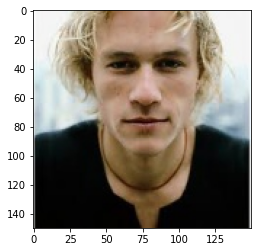

In [134]:
first=cv2.imread("image22.jpg")
plot(first)

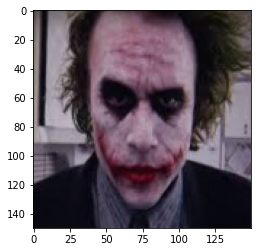

In [135]:
second=cv2.imread("image23.jpg")
plot(second)

In [136]:
M=300

In [77]:
first_dots=np.array([[77,99],[90,97],[66,97],[51,80],[102,80],[110,65],[45,69],[77,76],[61,76],[68,77],[86,76],[93,76],[41,48],[41,22],[45,7],[56,1],[76,0],[110,0],[112,10],[113,25],[113,48],[77,66],[66,61],[88,61],[69,55],[83,50],[72,39],[50,39],[60,43],[51,31],[72,31],[82,29],[105,38],[94,41],[84,31],[104,30],[19,83],[1,86],[133,84],[147,89],[1,1],[1,149],[149,1],[149,149]])

second_dots=np.array([[73,136],[84,133],[64,135],[46,105],[100,112],[107,97],[41,93],[74,110],[45,90],[55,107],[92,108],[103,98],[38,69],[37,32],[42,11],[49,2],[80,3],[108,16],[113,32],[112,51],[110,75],[75,96],[64,92],[85,93],[66,84],[83,84],[71,63],[45,58],[59,76],[48,47],[68,54],[80,63],[104,63],[92,76],[81,56],[102,54],[13,114],[1,119],[128,109],[149,117],[1,1],[1,149],[149,1],[149,149]])

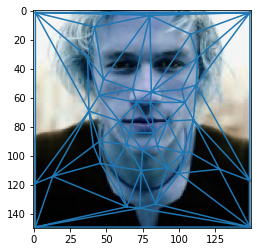

In [78]:
plt.imshow(first)
tri = Delaunay(second_dots)
plt.triplot(second_dots[:,0],second_dots[:,1],tri.simplices.copy())

we apply dot's in the bothe picture than use Delaunay algorithem the make them traingel thean change every same traingel to each other by moving them 

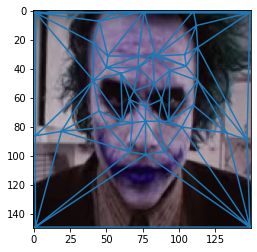

In [79]:
plt.imshow(second)
plt.triplot(first_dots[:,0], first_dots[:,1], tri.simplices.copy())

In [80]:
dots=np.array(tri.simplices)

In [81]:
def Affine_Transform(image, d1, d2, size) :
    
    warpMat = cv2.getAffineTransform( np.float32(d1), np.float32(d2) )
    
    dst = cv2.warpAffine( image, warpMat, (size[0], size[1]), None, flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101 )

    return dst

In [82]:
def get_rectangel(d):
    r=cv2.boundingRect(np.float32([d]))
    t=[]
    for i in range(3):
        t.append(((d[i][0] - r[0]),(d[i][1] - r[1])))
    return t,r

In [83]:
def morphing_rectangel(image1,image2,result,d1,d2,d,n):
    t1,r1=get_rectangel(d1)
    t2,r2=get_rectangel(d2)
    t,r=get_rectangel(d)
    
    mask = np.zeros((r[3],r[2],3), dtype = np.float32)
    cv2.fillConvexPoly(mask, np.int32(t), (1.0,1.0,1.0),16, 0)
    
    
    img1_Rect = image1[r1[1]:r1[1] + r1[3], r1[0]:r1[0] + r1[2]]
    img2_Rect = image2[r2[1]:r2[1] + r2[3], r2[0]:r2[0] + r2[2]]
    
    warp_image1 = Affine_Transform(img1_Rect,t1,t,(r[2], r[3]))
    warp_image2 = Affine_Transform(img2_Rect,t2,t,(r[2], r[3]))
    
    non_result=((M-n)/M)*warp_image1+(n/M)*warp_image2
    result[r[1]:r[1]+r[3],r[0]:r[0]+r[2]]=result[r[1]:r[1]+r[3],r[0]:r[0]+r[2]]*(1-mask)+non_result*mask

In [84]:
for n in range(M,-1,-1):
    new_point=[]
    final=np.zeros(first.shape)
    for j in range(first_dots.shape[0]):
        x = ((M-n)/M )* first_dots[j][0] +(n/M)*second_dots[j][0]
        y = ((M-n)/M )* first_dots[j][1] +(n/M)*second_dots[j][1]
        new_point.append((x,y))
    new_point=np.array(new_point,dtype='int')
    for j in range(dots.shape[0]):
        
        d =np.float32([new_point[dots[j,0]],new_point[dots[j,1]],new_point[dots[j,2]]])
        d1=np.float32([first_dots[dots[j,0]],first_dots[dots[j,1]],first_dots[dots[j,2]]])
        d2=np.float32([second_dots[dots[j,0]],second_dots[dots[j,1]],second_dots[dots[j,2]]])
#         print( n,"d1:",d1,"d2:",d2,"d:",d,"\n")
        
        morphing_rectangel(first,second,final,d1,d2,d,n)
    cv2.imwrite("/frame/"+str(n)+".jpg",final)

In [85]:
image_frame = []
for i in range(M):
    pltimage = cv2.imread("/frame/"+str(i)+".jpg")

    height, width, layers = pltimage.shape
    size = (width, height)
    image_frame.append(pltimage)

In [86]:
out = cv2.VideoWriter("/movie02.mp4", cv2.VideoWriter_fourcc(*'DIVX'),40, size)
for i in range(len(image_frame)):
    out.write(image_frame[i])
out.release()